# 03. Rolling-Horizon Simulation & Time Fence Enforcement — ROLLINGMRP

This notebook demonstrates Phase 2 capabilities:
1. **10-Week Dynamic Rolling-Horizon Simulation**
2. **Forecast Evolution vs. Ground Truth Realized Demand** (Horizon uncertainty decay)
3. **Plan Diffing & Change Classification** (Quantity changes, Timing shifts, Cancellations, New Orders)
4. **Frozen Time Fence Enforcement** (Blocking near-term churn to protect shop-floor stability)
5. **Physical Inventory Trajectories & Service Level Fulfillment**

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
current_dir = Path.cwd().resolve()
repo_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import asdict

from src.integration.data_generator import generate_synthetic_data
from src.integration.load import clean_and_validate_dataset, initialize_inventory_status
from src.core.explosion import BOMExplosionEngine
from src.rolling.horizon import RollingHorizonManager, DemandEvolutionModel
from src.rolling.frozen_window import PlanComparator, TimeFencePolicy

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Rolling Horizon simulation environment initialized. Root:", repo_root)

Rolling Horizon simulation environment initialized. Root: C:\zendvalmics\project\rolling-mrp


## 1. Setup Simulation Models & Policy
Configure a 10-week simulation with Frozen Window = 2 weeks (Weeks 0–1), Slushy = 2 weeks (Weeks 2–3), and Liquid = Weeks 4+.

In [2]:
raw_data = generate_synthetic_data(seed=42)
cleaned_data, _ = clean_and_validate_dataset(raw_data)
inv_df = initialize_inventory_status(cleaned_data["inventory"], cleaned_data["items"])

engine = BOMExplosionEngine(cleaned_data["bom"], cleaned_data["items"])
policy = TimeFencePolicy(frozen_periods=2, slushy_periods=2)
comparator = PlanComparator(policy)

fg_items = cleaned_data["items"][cleaned_data["items"]["type"] == "finished_good"]["item_id"].tolist()
managers = {}
for fg_id in fg_items:
    row = inv_df[inv_df["item_id"] == fg_id].iloc[0]
    managers[fg_id] = RollingHorizonManager(
        item_id=fg_id,
        window_length=12,
        firm_window_length=2,
        initial_on_hand=float(row["quantity_on_hand"]),
        initial_allocated=float(row["quantity_allocated"]),
        safety_stock=float(row["safety_stock"]),
        lead_time_periods=1,
        seed=hash(fg_id) % 10000,
    )

print(f"Configured rolling simulation for {len(fg_items)} finished goods across a 12-week planning window.")

Configured rolling simulation for 5 finished goods across a 12-week planning window.


## 2. Execute 10-Week Rolling Simulation Loop with Time Fence Enforcement

In [3]:
all_plan_changes = []
simulation_logs = []
previous_plan = []

for week in range(1, 11):
    curr_periods = managers[fg_items[0]].get_window_periods()
    mps_gross = {}
    for fg_id in fg_items:
        demands = managers[fg_id].get_window_demand()
        mps_gross[fg_id] = [d.quantity for d in demands]

    inv_dict = {}
    for _, row in inv_df.iterrows():
        iid = str(row["item_id"])
        if iid in managers:
            inv_dict[iid] = {
                "on_hand": managers[iid].on_hand,
                "allocated": managers[iid].allocated,
                "safety_stock": managers[iid].safety_stock,
                "lead_time_days": int(row["lead_time_days"]),
            }
        else:
            inv_dict[iid] = {
                "on_hand": float(row["quantity_on_hand"]),
                "allocated": float(row["quantity_allocated"]),
                "safety_stock": float(row["safety_stock"]),
                "lead_time_days": int(row["lead_time_days"]),
            }

    # Run MRP
    mrp_results, _ = engine.run_multi_level_mrp(mps_gross, curr_periods, inv_dict)

    raw_new_plan = []
    for itm, res in mrp_results.items():
        for po in res.planned_orders:
            raw_new_plan.append({
                "item_id": po.item_id,
                "due_period": po.due_period,
                "release_period": po.release_period,
                "quantity": po.quantity,
                "status": po.status,
            })

    # Enforce Time Fences
    enforced_plan, changes = comparator.enforce_time_fences(
        new_plan=raw_new_plan,
        previous_plan=previous_plan,
        current_period=week,
        allow_slushy_changes=True,
    )
    for ch in changes:
        ch_dict = ch.to_dict()
        ch_dict["planning_cycle"] = week
        all_plan_changes.append(ch_dict)

    # Advance period and fulfill actual demand
    for fg_id in fg_items:
        arrivals = [o for o in enforced_plan if o["item_id"] == fg_id and o["due_period"] == week + 1]
        for arr in arrivals:
            managers[fg_id].record_scheduled_receipt(week + 1, arr["quantity"])
        step_rec = managers[fg_id].advance_period(active_planned_orders=arrivals)
        step_dict = asdict(step_rec)
        step_dict["item_id"] = fg_id
        simulation_logs.append(step_dict)

    previous_plan = enforced_plan

df_changes = pd.DataFrame(all_plan_changes)
df_sim = pd.DataFrame(simulation_logs)
print(f"Simulation complete! Captured {len(df_changes)} plan change events across 10 planning cycles.")

Simulation complete! Captured 3378 plan change events across 10 planning cycles.


## 3. Visualize Demand Evolution: Actual Realized vs. Rolling Forecasts
Observe how forecast uncertainty increases with distance into the planning horizon.

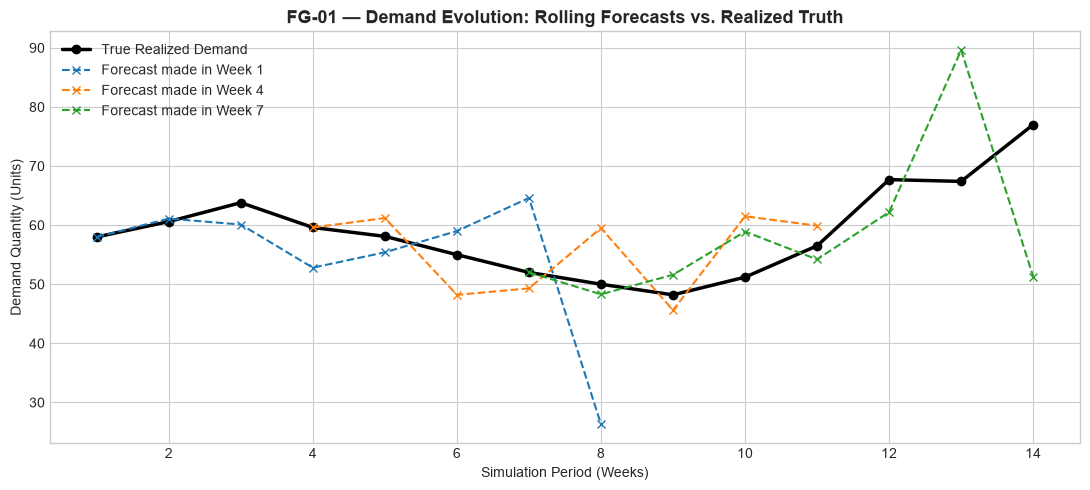

In [4]:
fg_sample = "FG-01"
m_sample = managers[fg_sample]
actual_demands = [m_sample.demand_model.get_ground_truth(p) for p in range(1, 15)]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(range(1, 15), actual_demands, marker="o", color="black", linewidth=2.5, label="True Realized Demand")

# Plot forecasts made from planning cycles 1, 4, and 7
for origin in [1, 4, 7]:
    horizons = range(origin, origin + 8)
    fc_vals = [m_sample.demand_model.generate_forecast(origin, h) for h in horizons]
    ax.plot(horizons, fc_vals, linestyle="--", marker="x", label=f"Forecast made in Week {origin}")

ax.set_title(f"{fg_sample} — Demand Evolution: Rolling Forecasts vs. Realized Truth", fontsize=13, fontweight="bold")
ax.set_xlabel("Simulation Period (Weeks)")
ax.set_ylabel("Demand Quantity (Units)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 4. Plan Changes Breakdown & Time Fence Enforcement
Analyze change classification (New Orders, Quantity Changes, Timing Shifts, Cancellations) and policy actions (BLOCKED in Frozen vs. ALLOWED in Liquid).

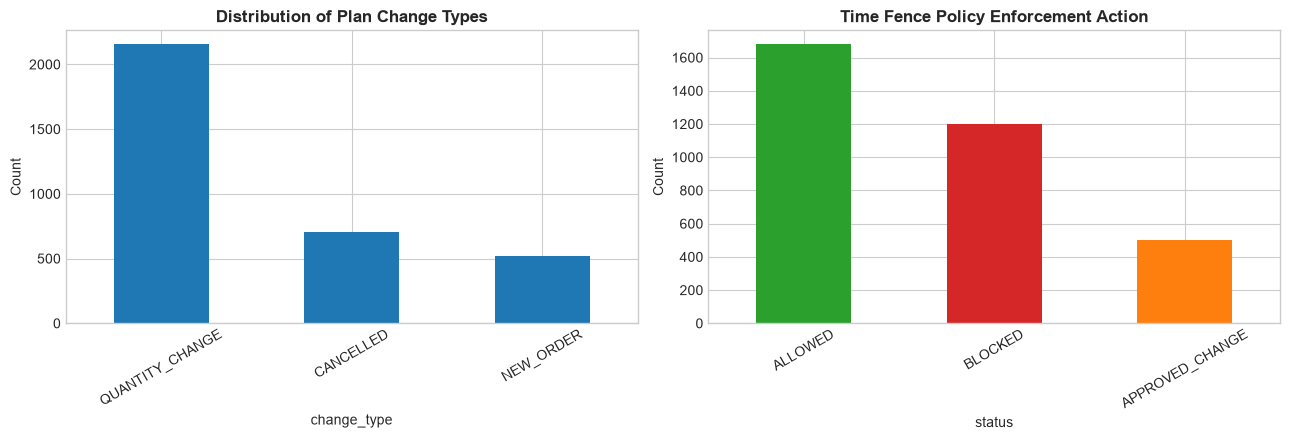

,planning_cycle,item_id,change_type,zone,status,description
0,1,FG-02,NEW_ORDER,FROZEN,BLOCKED,New order introduced in period 1 for 56.0 units
1,1,FG-02,NEW_ORDER,FROZEN,BLOCKED,New order introduced in period 2 for 61.3 units
2,1,FG-02,NEW_ORDER,SLUSHY,APPROVED_CHANGE,New order introduced in period 3 for 56.9 units
3,1,FG-02,NEW_ORDER,SLUSHY,APPROVED_CHANGE,New order introduced in period 4 for 59.1 units
4,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 5 for 60.4 units
5,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 6 for 55.2 units
6,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 7 for 70.5 units
7,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 8 for 53.9 units
8,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 9 for 15.2 units
9,1,FG-02,NEW_ORDER,LIQUID,ALLOWED,New order introduced in period 10 for 49.3 units


In [5]:
if not df_changes.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # 1. Change Types Distribution
    change_counts = df_changes["change_type"].value_counts()
    change_counts.plot(kind="bar", ax=axes[0], color="#1f77b4")
    axes[0].set_title("Distribution of Plan Change Types", fontweight="bold")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=30)

    # 2. Time Fence Action Distribution (Blocked vs Allowed)
    status_counts = df_changes["status"].value_counts()
    status_counts.plot(kind="bar", ax=axes[1], color=["#2ca02c", "#d62728", "#ff7f0e"][:len(status_counts)])
    axes[1].set_title("Time Fence Policy Enforcement Action", fontweight="bold")
    axes[1].set_ylabel("Count")
    axes[1].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()
    display(df_changes[["planning_cycle", "item_id", "change_type", "zone", "status", "description"]].head(15))
else:
    print("No plan changes detected across cycles.")

## 5. Physical Inventory & Customer Service Level Trajectory
Demonstrate inventory levels and fulfillments across the 10 weeks.

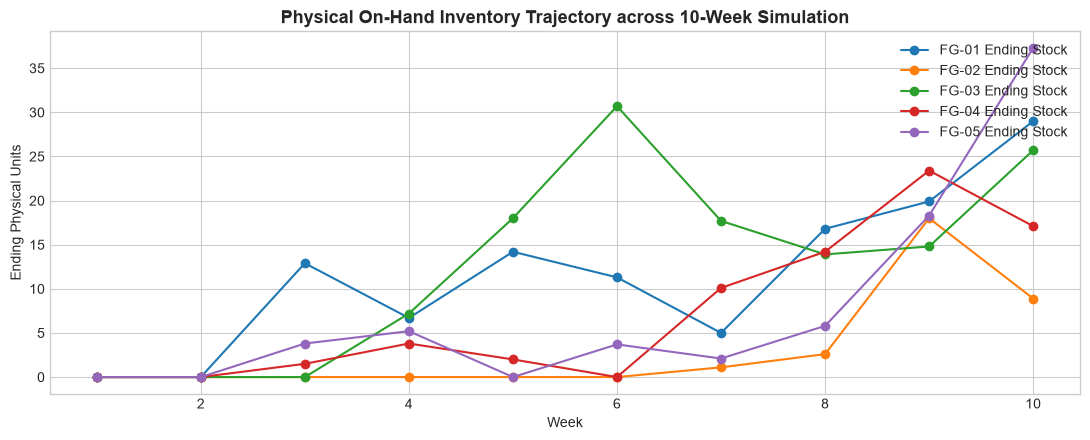

Total Factory Demand Served: 2277.0 / 2787.8 units
Realized Fill Rate / Service Level: 81.68%


In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for fg in fg_items:
    sub = df_sim[df_sim["item_id"] == fg]
    ax.plot(sub["period"], sub["ending_pab"], marker="o", label=f"{fg} Ending Stock")

ax.set_title("Physical On-Hand Inventory Trajectory across 10-Week Simulation", fontsize=13, fontweight="bold")
ax.set_xlabel("Week")
ax.set_ylabel("Ending Physical Units")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

total_demand = df_sim["demand_realized"].sum()
total_stockout = df_sim["stockout_units"].sum()
service_level = ((total_demand - total_stockout) / total_demand) * 100.0
print(f"Total Factory Demand Served: {total_demand - total_stockout:.1f} / {total_demand:.1f} units")
print(f"Realized Fill Rate / Service Level: {service_level:.2f}%")